# Crazy Cylinder Analysis

## individualAnalysis

In [1]:
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import curve_fit
from scipy.signal import lombscargle

mpl.rcParams['font.family']  = 'serif'
mpl.rcParams['font.serif']   = ['Computer Modern Roman']
mpl.rcParams['text.usetex']  = True
mpl.rcParams['axes.grid']    = False

# cylinder radius in meters
R = 0.011

# tank width for each confinement label
W = {
    'dw03':        0.066,
    'dw05':        0.044,
    'nonewtonian': 0.066,
    '0.5':         0.044,
    '0.333333':    0.066,
    '0.666667':    0.033,
}

# ── File readers ──────────────────────────────────────────────

def read_exp(file_path):
    """
    Read a rawExp file (dw03, dw05 or nonewtonian).
    Returns t, x, y as float arrays.
    Handles comma decimals and skips non-numeric rows.
    """
    try:
        data = pd.read_csv(
            file_path, sep=r'\s+', decimal=',',
            header=None, skiprows=2,
            names=['t', 'x', 'y'], on_bad_lines='skip'
        )
    except Exception:
        data = pd.read_csv(
            file_path, sep=r'\s+', decimal='.',
            header=None, skiprows=2,
            names=['t', 'x', 'y'], on_bad_lines='skip'
        )
    data = data.apply(pd.to_numeric, errors='coerce').dropna()
    return data['t'].values, data['x'].values, data['y'].values


def read_sim(file_path):
    """
    Read a simulation output file.
    Returns the first three columns as t, x, vx.
    """
    data = pd.read_csv(
        file_path, sep=r'\s+', decimal='.',
        header=0, on_bad_lines='skip'
    )
    data = data.apply(pd.to_numeric, errors='coerce').dropna()
    cols = data.columns.tolist()
    return data[cols[0]].values, data[cols[1]].values, data[cols[2]].values


# ── Spectral analysis ─────────────────────────────────────────

def compute_lombscargle(t, z, f_min=0.01, f_max=4.0, n_freq=1000):
#def compute_lombscargle(t, z, f_min=0.1, f_max=1.0, n_freq=1000):
    """
    Lomb-Scargle periodogram of z(t).
    Returns f_arr and power normalized to its maximum.
    """
    z_c   = z - np.mean(z)
    f_arr = np.linspace(f_min, f_max, n_freq)
    omega = 2 * np.pi * f_arr
    power = lombscargle(t, z_c, omega)
    power = power / np.max(power) if np.max(power) > 0 else power
    return f_arr, power


# ── Linear fit for pulling velocity ──────────────────────────

def linear(t, v, y0):
    return v * t + y0

def fit_velocity(t, y):
    (vy, y0), cov = curve_fit(linear, t, y)
    dvy = np.sqrt(np.diag(cov))[0]
    return vy, dvy, y0


# ── Helpers for plot_analysis ─────────────────────────────────

def _infer_dw_key(file_path):
    fp = file_path.lower()
    if 'nonewtonian' in fp: return 'nonewtonian'
    if 'dw03' in fp:        return 'dw03'
    if 'dw05' in fp:        return 'dw05'
    base  = os.path.basename(file_path)
    parts = base.replace('.txt', '').split('_')
    if parts[0] in W:       return parts[0]
    return 'dw03'

def _infer_output_dir(file_path, base_figures='../figures/individualAnalysis'):
    fp = file_path.lower()
    if 'nonewtonian' in fp:             return os.path.join(base_figures, 'exp', 'nonewtonian')
    if 'dw03' in fp:                    return os.path.join(base_figures, 'exp', 'dw03')
    if 'dw05' in fp:                    return os.path.join(base_figures, 'exp', 'dw05')
    if 'rawsim' in fp or 'sim' in fp:   return os.path.join(base_figures, 'sim')
    return os.path.join(base_figures, 'other')


# ── Individual file analysis ──────────────────────────────────

def plot_analysis(file_path, is_sim=False, show=True,
                  base_figures='../figures/individualAnalysis'):
    """
    Plot x(t), y(t) with linear fit (exp only), vx(t),
    and Lomb-Scargle spectra for a single file.
    """
    if is_sim:
        t, x, vx = read_sim(file_path)
        y = None
    else:
        t, x, y  = read_exp(file_path)
        vx       = np.gradient(x, t)

    dw_key = _infer_dw_key(file_path)
    w_val  = W[dw_key]
    x_lo   = R
    x_hi   = w_val - R

    f_x,  P_x  = compute_lombscargle(t, x)
    f_vx, P_vx = compute_lombscargle(t, vx)
    peak_x  = f_x[np.argmax(P_x)]
    peak_vx = f_vx[np.argmax(P_vx)]

    n_panels  = 3 if is_sim else 4
    fig, axes = plt.subplots(n_panels, 1, figsize=(8, 4 * n_panels), sharex=False)
    axes      = list(axes)
    fig.suptitle(os.path.basename(file_path), fontsize=13)
    ax_idx = 0

    # x vs t
    ax = axes[ax_idx]; ax_idx += 1
    ax.scatter(t, x, s=6, color='black', alpha=0.6, label=r'$x$')
    ax.set_ylabel(r'$x$ [m]', fontsize=12)
    ax.set_xlabel(r'$t$ [s]', fontsize=12)
    ax.legend(fontsize=12)

    # y vs t + linear fit (experimental only)
    if not is_sim:
        ax = axes[ax_idx]; ax_idx += 1
        vy, dvy, y0 = fit_velocity(t, y)
        t_fit = np.linspace(t.min(), t.max(), 300)
        ax.scatter(t, y, s=6, color='black', alpha=0.6, label=r'$y$')
        ax.plot(t_fit, linear(t_fit, vy, y0), color='red', lw=1.8,
                label=rf'$v_y = {vy:.4f} \pm {dvy:.4f}$ m/s')
        ax.set_ylabel(r'$y$ [m]', fontsize=12)
        ax.set_xlabel(r'$t$ [s]', fontsize=12)
        ax.legend(fontsize=12)

    # vx vs t
    ax = axes[ax_idx]; ax_idx += 1
    ax.scatter(t, vx, s=6, color='black', alpha=0.6, label=r'$v_x$')
    ax.set_ylabel(r'$v_x$ [m/s]', fontsize=12)
    ax.set_xlabel(r'$t$ [s]', fontsize=12)
    ax.legend(fontsize=12)

    # Lomb-Scargle
    ax = axes[ax_idx]; ax_idx += 1
    ax.plot(f_x,  P_x,  color='blue', lw=1.5, label=r'LS $x$')
    ax.plot(f_vx, P_vx, color='red',  lw=1.5, label=r'LS $v_x$')
    ax.scatter(peak_x,  P_x[np.argmax(P_x)],   color='blue', zorder=5, s=50,
               label=rf'Peak $x$ $=$ {peak_x:.3f} Hz')
    ax.scatter(peak_vx, P_vx[np.argmax(P_vx)], color='red',  zorder=5, s=50,
               label=rf'Peak $v_x$ $=$ {peak_vx:.3f} Hz')
    ax.set_xscale('log')
    ax.set_xlabel(r'Frequency [Hz]', fontsize=12)
    ax.set_ylabel(r'Normalized PSD',  fontsize=12)
    ax.legend(fontsize=12)

    fig.tight_layout()

    if show:
        plt.show()
    else:
        out_dir  = _infer_output_dir(file_path, base_figures)
        os.makedirs(out_dir, exist_ok=True)
        out_name = os.path.basename(file_path).replace('.txt', '_analysis.pdf')
        out_path = os.path.join(out_dir, out_name)
        fig.savefig(out_path, dpi=300)
        plt.close(fig)
        print(f"Saved: {out_path}")


### specific file

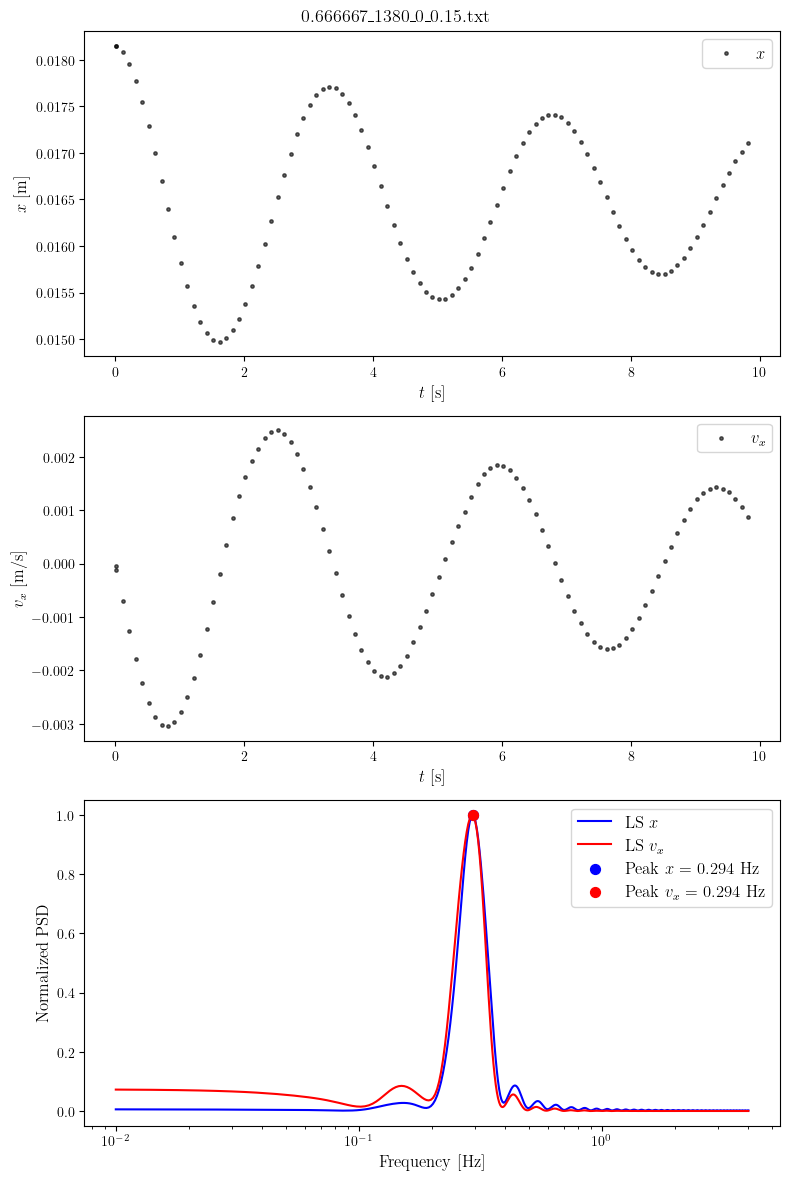

In [5]:
plot_analysis('../data/rawSim/natFreq/0.666667_1380_0_0.15.txt', is_sim=True, show=True)

## preprocessing

### Mappings, constants & peak_freq

In [25]:
# ── Cylinder / confinement mappings ───────────────────────────
rhoS_to_c   = {1030: 'c1', 1105: 'c2', 1270: 'c5', 1380: 'c6'}
c_to_rhoS   = {'c1': 1030, 'c2': 1105, 'c5': 1270, 'c6': 1380}
dw_to_label = {'0.5': 'dw05', '0.333333': 'dw03', '0.666667': 'dw06'}

# nominal experimental velocities
v_nominal = {'v1': 0.023, 'v2': 0.044, 'v3': 0.078, 'v4': 0.111, 'v5': 0.143}

# base paths
BASE_EXP   = '../data/rawExp'
BASE_SIM   = '../data/rawSim/txt'
BASE_SWEEP = '../data/rawSim/sweep'
BASE_NN    = '../data/rawExp/nonewtonian'

D = 2 * R   # cylinder diameter

# plot style per confinement
style = {
    'dw05': {'color': 'tab:blue',   'label': '$D/W=1/2$'},
    'dw03': {'color': 'tab:orange', 'label': '$D/W=1/3$'},
    'dw06': {'color': 'tab:green',  'label': '$D/W=2/3$'},
}

# ── Strouhal / analytic frequency ────────────────────────────
FEY_COEFFS = [
    (360,   1300,  0.2257, -0.4402),
    (1300,  5000,  0.2040,  0.3364),
    (5000,  2e5,   0.1776,  2.2023),
]

def strouhal_fey(Re):
    for Re_lo, Re_hi, Sr_star, m in FEY_COEFFS:
        if Re_lo <= Re < Re_hi:
            return Sr_star + m / np.sqrt(Re)
    return None

def analytic_freq(V, W_val):
    nu  = 1e-6
    G   = W_val - D
    V_G = V * W_val / G
    Re  = V_G * D / nu
    St  = 0.1776
    if G <= 0:
        return np.nan
    return St * V_G / D

# ── Filename parsers ──────────────────────────────────────────

def parse_exp_filename(fname):
    """'03c1v1m1.txt' → {'dw': 'dw03', 'c': 'c1', 'v': 'v1', 'm': '1'}"""
    base = os.path.basename(fname).replace('.txt', '')
    m    = re.match(r'^(03|05)(c\d)(v\d)(m\d)$', base)
    if not m: return None
    return {'dw': 'dw' + m.group(1), 'c': m.group(2),
            'v': m.group(3), 'm': m.group(4)}

def parse_sim_filename(fname):
    """'0.5_1030_0.012.txt' → {'dw_num', 'dw', 'rhoS', 'vin'}"""
    base  = os.path.basename(fname).replace('.txt', '')
    parts = base.split('_')
    if len(parts) != 3: return None
    try:
        dw_num = parts[0]
        return {'dw_num': dw_num, 'dw': dw_to_label.get(dw_num),
                'rhoS': float(parts[1]), 'vin': float(parts[2])}
    except ValueError:
        return None

def parse_sweep_filename(fname):
    """
    '0.333333_1380_0.023_1_0.6_4.txt'
    → {'dw', 'rhoS', 'vin', 'mulabel', 'l', 'm'}
    """
    base  = os.path.basename(fname).replace('.txt', '')
    parts = base.split('_')
    if len(parts) != 6: return None
    try:
        return {
            'dw':      parts[0],
            'rhoS':    float(parts[1]),
            'vin':     float(parts[2]),
            'mulabel': float(parts[3]),
            'l':       float(parts[4]),
            'm':       int(parts[5]),
        }
    except ValueError:
        return None

# ── Dominant frequency from Lomb-Scargle ─────────────────────

def peak_freq(t, x, vx):
    """Max peak between the LS of x and LS of vx."""
    _, Px  = compute_lombscargle(t, x)
    _, Pvx = compute_lombscargle(t, vx)
    f_arr  = np.linspace(0.01, 4.0, 1000)
    #return max(f_arr[np.argmax(Px)], f_arr[np.argmax(Pvx)])
    return f_arr[np.argmax(Pvx)]

### Pre-compute Frequencies

In [26]:
# Results are stored in two dicts:
#   exp_freq[(dw_label, rhoS, v_key)] = {'freq_mean', 'freq_std', 'vel_mean', 'vel_std', 'n'}
#   nn_freq[(ratio_code, v_key)]      = {'mean', 'std', 'n'}

exp_freq = {}
nn_freq  = {}

# ── dw03 and dw05 ─────────────────────────────────────────────
for dw_label in ['dw03', 'dw05']:
    folder = os.path.join(BASE_EXP, dw_label)
    dw_num = '03' if dw_label == 'dw03' else '05'

    for rhoS, c_key in sorted(rhoS_to_c.items()):
        for v_key in ['v1', 'v2', 'v3', 'v4', 'v5']:
            freqs_m = []
            vels_m  = []
            for m_key in ['m1', 'm2', 'm3', 'm4']:
                fname = f"{dw_num}{c_key}{v_key}{m_key}.txt"
                fpath = os.path.join(folder, fname)
                if not os.path.exists(fpath):
                    continue
                try:
                    t, x, y  = read_exp(fpath)
                    vx       = np.gradient(x, t)
                    vy, _, _ = fit_velocity(t, y)
                    freqs_m.append(peak_freq(t, x, vx))
                    vels_m.append(abs(vy))
                except Exception as e:
                    print(f"  WARN {fname}: {e}")

            if freqs_m:
                exp_freq[(dw_label, rhoS, v_key)] = {
                    'freq_mean': np.mean(freqs_m),
                    'freq_std':  np.std(freqs_m),
                    'vel_mean':  np.mean(vels_m),
                    'vel_std':   np.std(vels_m),
                    'n':         len(freqs_m),
                }

print(f"exp_freq: {len(exp_freq)} entries computed")

# ── Non-Newtonian ─────────────────────────────────────────────
nn_ratios = {'000': 0.00, '025': 0.25, '040': 0.40}

for ratio_code in ['000', '025', '040']:
    for v_key in ['v1', 'v5']:
        freqs_m = []
        for m_key in ['m1', 'm2', 'm3', 'm4']:
            fname = f"{ratio_code}{v_key}{m_key}.txt"
            fpath = os.path.join(BASE_NN, fname)
            if not os.path.exists(fpath):
                continue
            try:
                t, x, y = read_exp(fpath)
                vx      = np.gradient(x, t)
                freqs_m.append(peak_freq(t, x, vx))
            except Exception as e:
                print(f"  WARN {fname}: {e}")

        if freqs_m:
            nn_freq[(ratio_code, v_key)] = {
                'mean': np.mean(freqs_m),
                'std':  np.std(freqs_m),
                'n':    len(freqs_m),
            }

print(f"nn_freq:  {len(nn_freq)} entries computed")

exp_freq: 40 entries computed
nn_freq:  6 entries computed


In [27]:
from collections import defaultdict

sim_freq = {}

def _trim_and_aggregate(freqs):
    """
    4 repetitions  → use all.
    More than 4    → discard highest and lowest, use the rest.
    Returns mean, std, n_used.
    """
    n = len(freqs)
    if n <= 4:
        return np.mean(freqs), np.std(freqs), n
    trimmed = sorted(freqs)[1:-1]   # drop min and max
    return np.mean(trimmed), np.std(trimmed), len(trimmed)

# group repetitions by config key
_groups = defaultdict(list)

for fpath in sorted(glob.glob(os.path.join(BASE_SWEEP, '*.txt'))):
    info = parse_sweep_filename(fpath)
    if info is None:
        print(f"  WARN skip: {os.path.basename(fpath)}")
        continue
    key = (info['dw'], info['rhoS'], info['vin'], info['mulabel'], info['l'])
    try:
        t, x, vx = read_sim(fpath)
        f        = peak_freq(t, x, vx)
        _groups[key].append(f)
    except Exception as e:
        print(f"  WARN {os.path.basename(fpath)}: {e}")

for key, freqs in _groups.items():
    mean, std, n_used = _trim_and_aggregate(freqs)
    sim_freq[key] = {
        'mean':    mean,
        'std':     std,
        'n':       n_used,
        'n_total': len(freqs),   # total repetitions found before trimming
    }

print(f"sim_freq: {len(sim_freq)} configurations computed")

# quick sanity check
for key, freqs in _groups.items():
    mean, std, n_used = _trim_and_aggregate(freqs)
    sim_freq[key] = {
        'mean':    mean,
        'std':     std,
        'n':       n_used,
        'n_total': len(freqs),
    }
    if len(freqs) > 4:
        dw, rhoS, vin, mulabel, l = key
        print(f"  TRIMMED dw={dw}  rhoS={rhoS}  vin={vin}  mu={mulabel}  l={l}"
              f"  →  n_total={len(freqs)}  n_used={n_used}"
              f"  f={mean:.4f} ± {std:.4f} Hz")

sim_freq: 189 configurations computed
  TRIMMED dw=0.5  rhoS=1105.0  vin=0.078  mu=1.0  l=0.6  →  n_total=10  n_used=8  f=1.2297 ± 0.0776 Hz
  TRIMMED dw=0.5  rhoS=1105.0  vin=0.111  mu=1.0  l=0.6  →  n_total=10  n_used=8  f=1.7529 ± 0.4888 Hz
  TRIMMED dw=0.5  rhoS=1270.0  vin=0.078  mu=1.0  l=0.6  →  n_total=10  n_used=8  f=0.8422 ± 0.2392 Hz
  TRIMMED dw=0.5  rhoS=1270.0  vin=0.111  mu=1.0  l=0.6  →  n_total=10  n_used=8  f=1.7469 ± 0.2354 Hz


In [28]:
# ══════════════════════════════════════════════════════════════
# CELDA — Maximum amplitude per simulation repetition
#         + end-of-lock-in velocity per confinement
# ══════════════════════════════════════════════════════════════
D_CYL = 0.022   # cylinder diameter [m]
W['dw06']  = 0.033   # add dw06 entry if not already in W
MU_STD     = 1.0
L_STD      = 0.6

sim_amp    = {}
lock_out_v = {}
dw_num_inv = {'dw05': '0.5', 'dw03': '0.333333', 'dw06': '0.666667'}

for fpath in sorted(glob.glob(os.path.join(BASE_SWEEP, '*.txt'))):
    info = parse_sweep_filename(fpath)
    if info is None:
        continue
    key   = (info['dw'], info['rhoS'], info['vin'],
              info['mulabel'], info['l'], info['m'])
    w_val = D_CYL / float(info['dw'])
    try:
        _, x, _ = read_sim(fpath)
        sim_amp[key] = np.max(np.abs(x - w_val / 2))
    except Exception as e:
        print(f"  WARN {os.path.basename(fpath)}: {e}")

print(f"sim_amp: {len(sim_amp)} repetitions computed")

# ── End-of-lock-in per confinement ────────────────────────────
for dw_label in ['dw05', 'dw03', 'dw06']:
    dw_num = dw_num_inv[dw_label]

    v_amps = defaultdict(list)
    for (kdw, krhoS, kvin, kmu, kl, km), amp in sim_amp.items():
        if kdw != dw_num:                              continue
        if not np.isclose(krhoS, 1030,    atol=0.5):  continue
        if not np.isclose(kmu,   MU_STD,  atol=1e-6): continue
        if not np.isclose(kl,    L_STD,   atol=1e-6): continue
        v_amps[kvin].append(amp)

    if len(v_amps) < 2:
        continue

    vins_sorted = sorted(v_amps.keys())
    lock_found  = False

    for i in range(len(vins_sorted) - 1):
        v_lo      = vins_sorted[i]
        v_hi      = vins_sorted[i + 1]
        max_lo    = max(v_amps[v_lo])
        min_hi    = min(v_amps[v_hi])

        if min_hi < max_lo / 2:
            lock_out_v[dw_label] = (v_lo + v_hi) / 2
            print(f"  {dw_label}: first drop below half at "
                  f"V={v_lo:.3f} → V={v_hi:.3f} m/s  "
                  f"(max_lo={max_lo*1000:.2f} mm, min_hi={min_hi*1000:.2f} mm)  "
                  f"→ lock-out at V={lock_out_v[dw_label]:.4f} m/s")
            lock_found = True
            break

    if not lock_found:
        print(f"  {dw_label}: no lock-out detected")

sim_amp: 780 repetitions computed
  dw05: first drop below half at V=0.050 → V=0.056 m/s  (max_lo=10.53 mm, min_hi=2.48 mm)  → lock-out at V=0.0530 m/s
  dw03: first drop below half at V=0.078 → V=0.083 m/s  (max_lo=20.97 mm, min_hi=4.33 mm)  → lock-out at V=0.0805 m/s
  dw06: first drop below half at V=0.029 → V=0.034 m/s  (max_lo=5.40 mm, min_hi=0.38 mm)  → lock-out at V=0.0315 m/s


In [29]:
# ══════════════════════════════════════════════════════════════
# CELDA — Natural frequency per (dw, rhoS) configuration
# ══════════════════════════════════════════════════════════════
# Files: data/rawSim/natFreq/{dw}_{rhoS}_0_{displacement}.txt
# 4 displacements per config: 0.1, 0.15, 0.2, 0.25
# dw   : 0.5, 0.333333, 0.666667
# rhoS : 1030, 1380

BASE_NAT = '../data/rawSim/natFreq'

def parse_natfreq_filename(fname):
    """'{dw}_{rhoS}_0_{displacement}.txt' → {'dw', 'rhoS', 'displacement'}"""
    base  = os.path.basename(fname).replace('.txt', '')
    parts = base.split('_')
    if len(parts) != 4:
        return None
    try:
        return {
            'dw':           parts[0],
            'rhoS':         float(parts[1]),
            'displacement': float(parts[3]),
        }
    except ValueError:
        return None

# group by (dw, rhoS)
_nat_groups = defaultdict(list)

for fpath in sorted(glob.glob(os.path.join(BASE_NAT, '*.txt'))):
    info = parse_natfreq_filename(fpath)
    if info is None:
        print(f"  WARN skip: {os.path.basename(fpath)}")
        continue
    try:
        t, x, vx = read_sim(fpath)
        f         = peak_freq(t, x, vx)
        _nat_groups[(info['dw'], info['rhoS'])].append(f)
    except Exception as e:
        print(f"  WARN {os.path.basename(fpath)}: {e}")

# nat_freq[(dw_str, rhoS)] = {'mean', 'std', 'n'}
nat_freq = {}
for (dw_str, rhoS), freqs in sorted(_nat_groups.items()):
    nat_freq[(dw_str, rhoS)] = {
        'mean': np.mean(freqs),
        'std':  np.std(freqs),
        'n':    len(freqs),
    }

# ── Print table ───────────────────────────────────────────────
dw_label_map = {'0.5': 'D/W=1/2', '0.333333': 'D/W=1/3', '0.666667': 'D/W=2/3'}

header = f"{'D/W':<12} {'rhoS':>8}   {'f_n [Hz]':>18}   {'n':>4}"
print(header)
print('-' * len(header))
for (dw_str, rhoS), v in sorted(nat_freq.items()):
    label = dw_label_map.get(dw_str, dw_str)
    print(f"{label:<12} {rhoS:>8.0f}   "
          f"{v['mean']:>8.4f} ± {v['std']:>7.4f} Hz   {v['n']:>4}")

D/W              rhoS             f_n [Hz]      n
-------------------------------------------------
D/W=1/3          1030     0.1977 ±  0.0224 Hz      4
D/W=1/3          1380     0.2307 ±  0.0192 Hz      4
D/W=1/2          1030     0.2227 ±  0.0052 Hz      4
D/W=1/2          1380     0.2556 ±  0.0060 Hz      4
D/W=2/3          1030     0.2596 ±  0.0060 Hz      4
D/W=2/3          1380     0.2936 ±  0.0075 Hz      4


## velvsfreq

In [30]:
from scipy.optimize import curve_fit as _curve_fit


v_nom_set  = set(v_nominal.values())
dw_num_inv = {'dw05': '0.5', 'dw03': '0.333333', 'dw06': '0.666667'}


# ── Individual-point accessors (for mean=False) ───────────────

def _get_sim_individual(rhoS, dw_label, only_nominal=True):
    """List of (vin, freq) for every repetition file."""
    dw_num = dw_num_inv[dw_label]
    points = []
    for fpath in sorted(glob.glob(os.path.join(BASE_SWEEP, '*.txt'))):
        info = parse_sweep_filename(fpath)
        if info is None:                                          continue
        if info['dw'] != dw_num:                                  continue
        if not np.isclose(info['rhoS'],    rhoS,    atol=0.5):   continue
        if not np.isclose(info['mulabel'], MU_STD,  atol=1e-6):  continue
        if not np.isclose(info['l'],       L_STD,   atol=1e-6):  continue
        if only_nominal and not any(np.isclose(info['vin'], v, atol=1e-4)
                                    for v in v_nom_set):          continue
        try:
            t, x, vx = read_sim(fpath)
            points.append((info['vin'], peak_freq(t, x, vx)))
        except Exception as e:
            print(f"  WARN {os.path.basename(fpath)}: {e}")
    return points


def _get_exp_individual(rhoS, dw_label):
    """List of (vel, freq) for every experimental repetition file."""
    folder = os.path.join(BASE_EXP, dw_label)
    dw_num = '03' if dw_label == 'dw03' else '05'
    c_key  = rhoS_to_c[rhoS]
    points = []
    for v_key in ['v1', 'v2', 'v3', 'v4', 'v5']:
        for m_key in ['m1', 'm2', 'm3', 'm4']:
            fname = f"{dw_num}{c_key}{v_key}{m_key}.txt"
            fpath = os.path.join(folder, fname)
            if not os.path.exists(fpath):
                continue
            try:
                t, x, y  = read_exp(fpath)
                vx       = np.gradient(x, t)
                vy, _, _ = fit_velocity(t, y)
                points.append((abs(vy), peak_freq(t, x, vx)))
            except Exception as e:
                print(f"  WARN {fname}: {e}")
    return points

# ── Accessors into pre-computed dicts ─────────────────────────

def _get_exp(rhoS, dw_label):
    """vel_mean, vel_std, freq_mean, freq_std ordered by v_key."""
    vms, vss, fms, fss = [], [], [], []
    for v_key in ['v1', 'v2', 'v3', 'v4', 'v5']:
        e = exp_freq.get((dw_label, rhoS, v_key))
        if e is None:
            continue
        vms.append(e['vel_mean']); vss.append(e['vel_std'])
        fms.append(e['freq_mean']); fss.append(e['freq_std'])
    return tuple(np.array(a) for a in (vms, vss, fms, fss))

def _get_sim(rhoS, dw_label, only_nominal=True):
    """vin, freq_mean, freq_std from sim_freq for standard mu/l."""
    dw_num = dw_num_inv[dw_label]
    rows   = []
    for (kdw, krhoS, kvin, kmu, kl), val in sim_freq.items():
        if kdw != dw_num:                              continue
        if not np.isclose(krhoS, rhoS,    atol=0.5):  continue
        if not np.isclose(kmu,   MU_STD,  atol=1e-6): continue
        if not np.isclose(kl,    L_STD,   atol=1e-6): continue
        if only_nominal and not any(np.isclose(kvin, v, atol=1e-4)
                                    for v in v_nom_set):
            continue
        rows.append((kvin, val['mean'], val['std']))
    if not rows:
        return np.array([]), np.array([]), np.array([])
    rows.sort()
    return tuple(np.array([r[i] for r in rows]) for i in range(3))

# ── Analytic model with St as free parameter ──────────────────

def _model(V, St, W_val):
    return St * (V * W_val / (W_val - D)) / D

def _fit_analytic(V_data, f_data, W_val):
    """Fit St and return St, R²."""
    popt, _ = _curve_fit(
        lambda V, St: _model(V, St, W_val),
        V_data, f_data, p0=[0.18]
    )
    St_fit = popt[0]
    f_pred = _model(V_data, St_fit, W_val)
    ss_res = np.sum((f_data - f_pred) ** 2)
    ss_tot = np.sum((f_data - np.mean(f_data)) ** 2)
    R2     = 1 - ss_res / ss_tot
    return St_fit, R2

def _solve_delangre(Vr, St, Vr_lo):
    """
    Solves de Langre (2006) linear coupled-mode flutter equation:
        w^4 + [(AM - 1)*Omega^2 - 1]*w^2 + Omega^2 = 0
    where Omega = St * Vr, returning real frequency branches (f / f_n).
    """
    AM = (1-1/(St * Vr_lo))**2
    
    Omega = St * Vr
    b = (1.0 - AM) * (Omega**2) + 1.0  # -B term
    disc = b**2 - 4.0 * (Omega**2)
    

    w_R1 = np.zeros_like(Vr)
    w_R2 = np.zeros_like(Vr)
    
    # Outside lock-in (disc >= 0): two distinct real branches
    mask_real = disc >= 0
    if np.any(mask_real):
        b_m = b[mask_real]
        d_m = np.sqrt(disc[mask_real])
        w2_plus  = (b_m + d_m) / 2.0
        w2_minus = (b_m - d_m) / 2.0
        w_R1[mask_real] = np.sqrt(np.maximum(0, w2_plus))
        w_R2[mask_real] = np.sqrt(np.maximum(0, w2_minus))
        
    # Inside lock-in (disc < 0): merged CMF branch
    mask_cmf = disc < 0
    if np.any(mask_cmf):
        w_cmf = np.sqrt((Omega[mask_cmf] + b[mask_cmf] / 2.0) / 2.0)
        w_R1[mask_cmf] = w_cmf
        w_R2[mask_cmf] = w_cmf
        
    return w_R1, w_R2, AM


def _get_sim_amp(rhoS, dw_label):
    dw_num = dw_num_inv[dw_label]
    rows   = []
    for (kdw, krhoS, kvin, kmu, kl, km), amp in sim_amp.items():
        if kdw != dw_num:                              continue
        if not np.isclose(krhoS, rhoS,    atol=0.5):  continue
        if not np.isclose(kmu,   MU_STD,  atol=1e-6): continue
        if not np.isclose(kl,    L_STD,   atol=1e-6): continue
        rows.append((kvin, amp))
    if not rows:
        return np.array([]), np.array([])
    rows.sort()
    return tuple(np.array([r[i] for r in rows]) for i in range(2))

# ── Plot 1: 4-panel, all cylinders, dw03 & dw05 ──────────────
def plot_vel_vs_freq_comparison(show=True, base_figures='../figures'):
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    axes = axes.flatten()

    global_errors = []

    for ax_i, (rhoS, c_key) in enumerate(sorted(rhoS_to_c.items())):
        ax = axes[ax_i]

        for dw_label in ['dw05', 'dw03']:
            col   = style[dw_label]['color']
            label = style[dw_label]['label']

            # split exp points by n
            vms4, vss4, fms4, fss4 = [], [], [], []
            vms3, vss3, fms3, fss3 = [], [], [], []

            for v_key in ['v1', 'v2', 'v3', 'v4', 'v5']:
                e = exp_freq.get((dw_label, rhoS, v_key))
                if e is None:
                    continue
                if e['n'] >= 4:
                    vms4.append(e['vel_mean']); vss4.append(e['vel_std'])
                    fms4.append(e['freq_mean']); fss4.append(e['freq_std'])
                else:
                    vms3.append(e['vel_mean']); vss3.append(e['vel_std'])
                    fms3.append(e['freq_mean']); fss3.append(e['freq_std'])

            if vms4:
                ax.errorbar(vms4, fms4, xerr=vss4, yerr=fss4,
                            fmt='o', color=col, capsize=4,
                            lw=1.5, ms=10, alpha=1.0, mfc='white',
                            label=rf'{label} Exp')
            if vms3:
                ax.errorbar(vms3, fms3, xerr=vss3, yerr=fss3,
                            fmt='*', color=col, capsize=4,
                            lw=1.5, ms=15, alpha=1.0, mfc='white',
                            label=rf'{label} Exp (n=3)')

            vins, fmeans, fstds = _get_sim(rhoS, dw_label, only_nominal=True)
            if len(vins):
                ax.errorbar(vins, fmeans, yerr=fstds,
                            fmt='o', color=col, capsize=4,
                            lw=1.5, ms=10, alpha=0.8,
                            label=rf'{label} Sim')

        ax.set_xlabel(r'$V$ [m/s]', fontsize=12)
        ax.set_ylabel(r'$f$ [Hz]',  fontsize=12)
        ax.text(0.05, 0.95, rf'$\rho_c = {rhoS}$ kg/m$^3$',
                transform=ax.transAxes, fontsize=12, va='top')
                
        # ── Per-cylinder error ────────────────────────────────
        cyl_errors = []
        for dw_label in ['dw05', 'dw03']:
            dw_num = dw_num_inv[dw_label]
            dw_errors = []
            for v_key in ['v1', 'v2', 'v3', 'v4', 'v5']:
                e = exp_freq.get((dw_label, rhoS, v_key))
                if e is None:
                    continue
                f_exp   = e['freq_mean']
                vin_nom = v_nominal[v_key]
                s = next(
                    (val for (kdw, krhoS, kvin, kmu, kl), val in sim_freq.items()
                     if kdw == dw_num
                     and np.isclose(krhoS, rhoS,    atol=0.5)
                     and np.isclose(kvin,  vin_nom, atol=1e-4)
                     and np.isclose(kmu,   MU_STD,  atol=1e-6)
                     and np.isclose(kl,    L_STD,   atol=1e-6)),
                    None
                )
                if s is not None:
                    err = abs(s['mean'] - f_exp) / f_exp * 100
                    dw_errors.append(err)
                    cyl_errors.append(err)
                    global_errors.append(err)

            if dw_errors:
                print(f"  {c_key} {dw_label}: "
                      f"mean rel error = {np.mean(dw_errors):.2f}%  "
                      f"({len(dw_errors)} points)")

        if cyl_errors:
            print(f"  {c_key} overall:  "
                  f"mean rel error = {np.mean(cyl_errors):.2f}%  "
                  f"({len(cyl_errors)} points)")
        print()

    if global_errors:
        print(f"Global mean relative error across all configs: "
              f"{np.mean(global_errors):.2f}%  ({len(global_errors)} points)")

    axes[0].legend(fontsize=10, frameon=False)

    fig.tight_layout()
    if show:
        plt.show()
    else:
        out_dir  = os.path.join(base_figures, 'velvsfreq')
        os.makedirs(out_dir, exist_ok=True)
        out_path = os.path.join(out_dir, 'vel_vs_freq_comparison.png')
        fig.savefig(out_path, dpi=300)
        plt.close(fig)
        print(f"Saved: {out_path}")


# ── Plot 2: c1 sweep — non-dimensional axes ───────────────────

def plot_vel_vs_freq_sweep(analytic=True, mean=True, show=True,
                           dw_labels=('dw05', 'dw03', 'dw06'), delangre=True, AM=0.5,
                           base_figures='../figures'):
    """
    Non-dimensional V_r = V/(f_n*D) vs f/f_n for rhoS=1030.
    mean=True  → plot mean ± std from pre-computed dicts.
    mean=False → plot every individual repetition as a scatter point.
    """
    rhoS = 1030
    fig, ax = plt.subplots(figsize=(8, 5))

    for dw_label in dw_labels:
        col   = style[dw_label]['color']
        label = style[dw_label]['label']
        W_val = W[dw_label]
        dw_str = dw_num_inv[dw_label]
        fn = nat_freq.get((dw_str, 1030), {}).get('mean')

        V_fit, f_fit = [], []   # for analytic fit (always in physical units)

        print(f"  {dw_label}: f_n = {fn:.4f} Hz")

        # ── Simulation ────────────────────────────────────────
        if mean:
            vins, fmeans, fstds = _get_sim(rhoS, dw_label, only_nominal=False)
            if len(vins):
                ax.errorbar(vins / (fn * D_CYL), fmeans / fn,
                            yerr=fstds / fn,
                            fmt='o', color='black', capsize=4,
                            lw=1.5, ms=7, alpha=0.8,
                            label=rf'{label} Sim')
                V_fit.extend(vins); f_fit.extend(fmeans)
        else:
            pts = _get_sim_individual(rhoS, dw_label, only_nominal=False)
            if pts:
                vv = np.array([p[0] for p in pts])
                ff = np.array([p[1] for p in pts])
                ax.scatter(vv / (fn * D_CYL), ff / fn,
                            marker='^', color='black', s=60,
                            alpha=0.6)
                ax.scatter(10,2, alpha=0, label=f'{label}')
                print(f"max(V_r)={np.max(vv/(fn*D_CYL)):.3f}, max(f/f_n)={np.max(ff/fn):.3f}")
                V_fit.extend(vv); f_fit.extend(ff)

        # ── Experimental ──────────────────────────────────────
        if dw_label != 'dw06':
            if mean:
                vms, vss, fms, fss = _get_exp(rhoS, dw_label)
                if len(vms):
                    Vr  = vms / (fn * D_CYL)
                    fn_ratio = fms / fn
                    ax.errorbar(Vr, fn_ratio,
                                xerr=vss / (fn * D_CYL),
                                yerr=fss / fn,
                                fmt='o', color='black', capsize=4,
                                lw=1.5, ms=6, alpha=0.8, mfc='white',
                                label=rf'{label} Exp')
                    V_fit.extend(vms); f_fit.extend(fms)
            else:
                pts = _get_exp_individual(rhoS, dw_label)
                if pts:
                    vv = np.array([p[0] for p in pts])
                    ff = np.array([p[1] for p in pts])
                    ax.scatter(vv / (fn * D_CYL), ff / fn,
                               marker='o', color='black', s=60,
                               alpha=0.8, facecolors='white', 
                                )#label='Experimental data')
                    V_fit.extend(vv); f_fit.extend(ff)

        # ── Analytic fit (in physical units, plotted non-dim) ─
        if analytic and len(V_fit) > 1:
            V_arr = np.array(V_fit)
            f_arr = np.array(f_fit)

            # filter: V_r < 5 OR f/f_n > 4
            mask  = (V_arr / (fn * D_CYL) < 5) | (f_arr / fn > 4)
            V_fit_filt = V_arr[mask]
            f_fit_filt = f_arr[mask]

            if len(V_fit_filt) > 1:
                try:
                    St_fit, R2 = _fit_analytic(V_fit_filt, f_fit_filt, W_val)
                    V_plot = np.linspace(V_arr.min(),
                                         V_arr.max(), 300)
                    ax.plot(V_plot / (fn * D_CYL),
                            _model(V_plot, St_fit, W_val) / fn,
                            color='black', ls='--', lw=1.5, alpha=0.9,
                            )#label=(f'Uncoupled solution'))
                except Exception as e:
                    print(f"  WARN fit {dw_label}: {e}")

        # ── de Langre (2006) model curves ────────────────────
        if delangre and St_fit is not None:
            # Confinement modification: St_mod = St_fit * (1 + (D/W)/(1 - D/W))
            blockage = D_CYL / W_val
            St_mod = St_fit * (1.0 + (blockage / (1.0 - blockage)))

            V_grid = np.linspace(V_arr.min(), V_arr.max(), 500)
            #V_grid = np.linspace(0.0, 36.0 * fn * D_CYL, 500)
            Vr_grid = V_grid / (fn * D_CYL)
            Vr_lo  = lock_out_v[dw_label] / (fn * D_CYL)
            w1, w2, AM = _solve_delangre(Vr_grid, St=St_mod, Vr_lo=Vr_lo)

            # Both branches plotted with solid line and matching dataset color
            ax.plot(Vr_grid, w1, color='black', ls='-', lw=1.5, alpha=0.8,
                    )#label=rf'Coupled-modes')
            ax.plot(Vr_grid, w2, color='black', ls='-', lw=1.5, alpha=0.8)

    ax.set_xlabel(r'$V_r$', fontsize=18)
    ax.set_ylabel(r'$f\,/\,f_n$',            fontsize=18)
    #Vr_lo  = lock_out_v[dw_label] / (fn * D_CYL)
    #ax.axvline(Vr_lo, color='black', ls=':', lw=1.5, alpha=0.8)
    ax.tick_params(axis='both', which='major', labelsize=15)
    #ax.set_xlim(0,36)
    #ax.set_ylim(0,16)
    #ax.text(0.03, 0.70, rf'{label}',
     #       transform=ax.transAxes, fontsize=18, va='top')
    ax.legend(fontsize=18, frameon=True)
    fig.tight_layout()

    if show:
        plt.show()
    else:
        out_dir  = os.path.join(base_figures, 'velvsfreq')
        os.makedirs(out_dir, exist_ok=True)
        tag      = 'mean' if mean else 'all'
        out_path = os.path.join(out_dir, f'vel_vs_freq_sweep_c1_{tag}.png')
        fig.savefig(out_path, dpi=300)
        plt.close(fig)
        print(f"Saved: {out_path}")


def plot_vel_vs_amp(dw_labels=('dw05', 'dw03', 'dw06'),
                    show=True, base_figures='../figures'):

    rhoS = 1030
    fig, ax = plt.subplots(figsize=(8, 5))

    for dw_label in dw_labels:
        col    = style[dw_label]['color']
        label  = style[dw_label]['label']
        dw_str = dw_num_inv[dw_label]
        fn     = nat_freq.get((dw_str, 1030), {}).get('mean')

        vins, amps = _get_sim_amp(rhoS, dw_label)
        if len(vins) == 0:
            continue

        Vr      = vins / (fn * D_CYL)
        amp_norm = amps / D_CYL
        Vr_lo  = lock_out_v[dw_label] / (fn * D_CYL)
        
        ax.axvline(Vr_lo, alpha=0, label=f'{label}')
        ax.scatter(Vr, amp_norm,
                   marker='^', color='black', s=60,
                   alpha=0.6, label='Simulation data', zorder=3)        
        ax.axvline(Vr_lo, color='black', ls=':', lw=1.5, alpha=0.8, label='Lock-out $V_r$')
        
        
    ax.set_xlabel(r'$V_r$', fontsize=18)
    ax.set_ylabel(r'$A/D$',                  fontsize=18)
    ax.tick_params(axis='both', which='major', labelsize=15)
    #ax.text(0.03, 0.70, rf'{label}',
     #           transform=ax.transAxes, fontsize=18, va='top')
    ax.legend(fontsize=18, frameon=True, loc='upper right')
    fig.tight_layout()

    if show:
        plt.show()
    else:
        out_dir  = os.path.join(base_figures, 'velvsamp')
        os.makedirs(out_dir, exist_ok=True)
        out_path = os.path.join(out_dir, 'vel_vs_amp.png')
        fig.savefig(out_path, dpi=300)
        plt.close(fig)
        print(f"Saved: {out_path}")


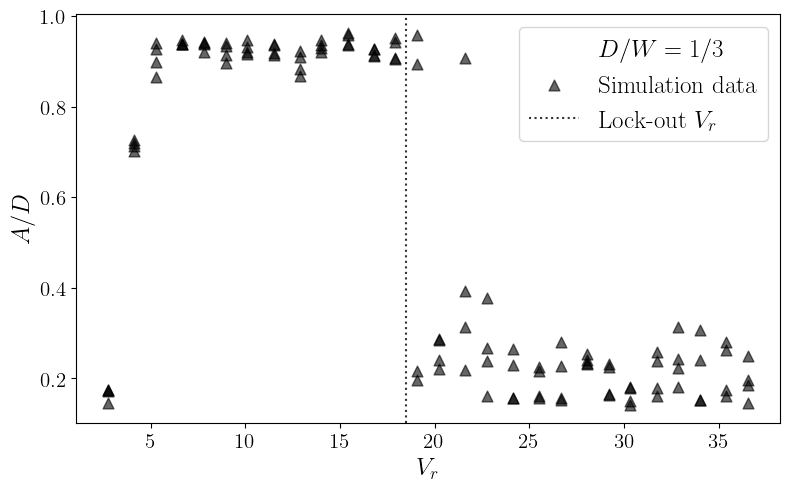

In [31]:
plot_vel_vs_amp(show=True, dw_labels=('dw03',))


  dw06: f_n = 0.2596 Hz
max(V_r)=27.837, max(f/f_n)=15.407


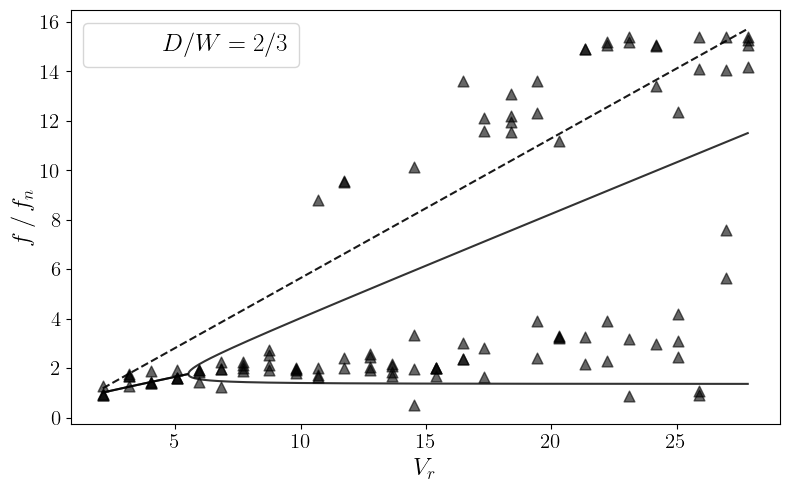

In [36]:
plot_vel_vs_freq_sweep(analytic=True, dw_labels= ('dw06',), delangre=True, mean=False, show=True)

## muvsfreq

Using f_n = 0.2307 Hz for mu sweep plots


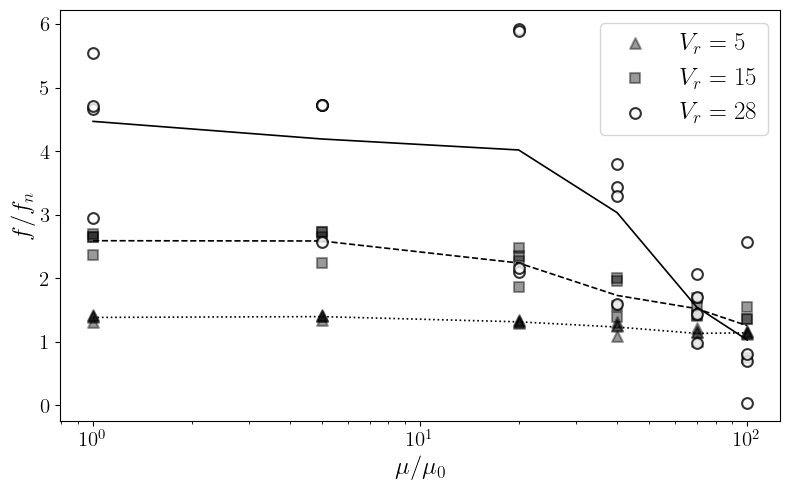

In [37]:

MU_DW   = '0.333333'
MU_RHOS = 1380.0
MU_L    = 0.6
fn     = nat_freq.get((MU_DW, 1380), {}).get('mean')
print(f"Using f_n = {fn:.4f} Hz for mu sweep plots")

mu_v_configs = {
    'v1': {'vin': 0.023, 'vr': 0.023/(fn*D_CYL), 'marker': '^', 'linestyle': ':', 'alpha': 0.4, 'facecolor': 'black'},
    'v3': {'vin': 0.078, 'vr': 0.078/(fn*D_CYL), 'marker': 's', 'linestyle': '--', 'alpha': 0.4, 'facecolor': 'black'},
    'v5': {'vin': 0.143, 'vr': 0.143/(fn*D_CYL), 'marker': 'o', 'linestyle': '-', 'alpha': 0.8, 'facecolor': 'white'},
}


def _get_sim_mu_individual(vin):
    """
    Pull every repetition file for fixed dw=1/3, rhoS=1380, l=0.6
    and the given vin. Returns list of (mulabel, freq).
    """
    points = []
    for fpath in sorted(glob.glob(os.path.join(BASE_SWEEP, '*.txt'))):
        info = parse_sweep_filename(fpath)
        if info is None:                                             continue
        if info['dw'] != MU_DW:                                      continue
        if not np.isclose(info['rhoS'],    MU_RHOS, atol=0.5):       continue
        if not np.isclose(info['vin'],     vin,     atol=1e-4):       continue
        if not np.isclose(info['l'],       MU_L,    atol=1e-6):       continue
        try:
            t, x, vx = read_sim(fpath)
            points.append((info['mulabel'], peak_freq(t, x, vx)))
        except Exception as e:
            print(f"  WARN {os.path.basename(fpath)}: {e}")
    return points

def _get_sim_mu(vin):
    """
    Pull all mulabel values for fixed dw=1/3, rhoS=1380, l=0.6
    and the given vin from sim_freq.
    Returns mu_vals, freq_means, freq_stds sorted by mulabel.
    """
    rows = []
    for (kdw, krhoS, kvin, kmu, kl), val in sim_freq.items():
        if kdw != MU_DW:                                continue
        if not np.isclose(krhoS, MU_RHOS, atol=0.5):   continue
        if not np.isclose(kvin,  vin,     atol=1e-4):   continue
        if not np.isclose(kl,    MU_L,    atol=1e-6):   continue
        rows.append((kmu, val['mean'], val['std']))
    if not rows:
        return np.array([]), np.array([]), np.array([])
    rows.sort()
    return tuple(np.array([r[i] for r in rows]) for i in range(3))


def plot_mu_vs_freq(mean=False, show=True, base_figures='../figures'):
    
    fig, ax = plt.subplots(figsize=(8, 5))

    for v_key, cfg in mu_v_configs.items():

        if mean:
            mu_arr, fmeans, fstds = _get_sim_mu(cfg['vin'])
            if len(mu_arr) == 0:
                continue
            #ax.errorbar(mu_arr, fmeans / fn, yerr=fstds / fn,
             ##          lw=1.5, ms=6, alpha=0.8,
               #         label=cfg['label'], zorder=3)
            ax.plot(mu_arr, fmeans / fn, linestyle=cfg['linestyle'], color='black',
                    lw=1.2, alpha=1.0, zorder=2)
            

        pts = _get_sim_mu_individual(cfg['vin'])
        if not pts:
            continue
        mu_vals = np.array([p[0] for p in pts])
        f_vals  = np.array([p[1] for p in pts])
        ax.scatter(mu_vals, f_vals / fn,
                    marker=cfg['marker'], color='black', s=60,
                    alpha=cfg['alpha'], facecolor=cfg['facecolor'],
                    linewidths=1.5,
                    label=f"$V_r={cfg['vr']:.0f}$", zorder=3)
    ax.set_xscale('log')
    #ax.set_yscale('log')
    ax.set_xlabel(r'$\mu/\mu_0$', fontsize=18)
    ax.tick_params(axis='both', which='major', labelsize=15)
    ax.set_ylabel(r'$f/f_n$',      fontsize=18)
    ax.legend(fontsize=18, frameon=True, loc='upper right')
    #ax.text(0.97, 0.70,
     #       '$D/W = 1/3$\n'
      #      r'$\rho_c = 1380$ kg/m$^3$',
       #     transform=ax.transAxes, fontsize=13,
        #    ha='right', va='bottom')
    fig.tight_layout()

    if show:
        plt.show()
    else:
        out_dir  = os.path.join(base_figures, 'muvsfreq')
        os.makedirs(out_dir, exist_ok=True)
        tag      = 'mean' if mean else 'all'
        out_path = os.path.join(out_dir, f'mu_vs_freq_{tag}.png')
        fig.savefig(out_path, dpi=300)
        plt.close(fig)
        print(f"Saved: {out_path}")


# ── Calls ─────────────────────────────────────────────────────
plot_mu_vs_freq(mean=True,  show=True)

## l sensitivity

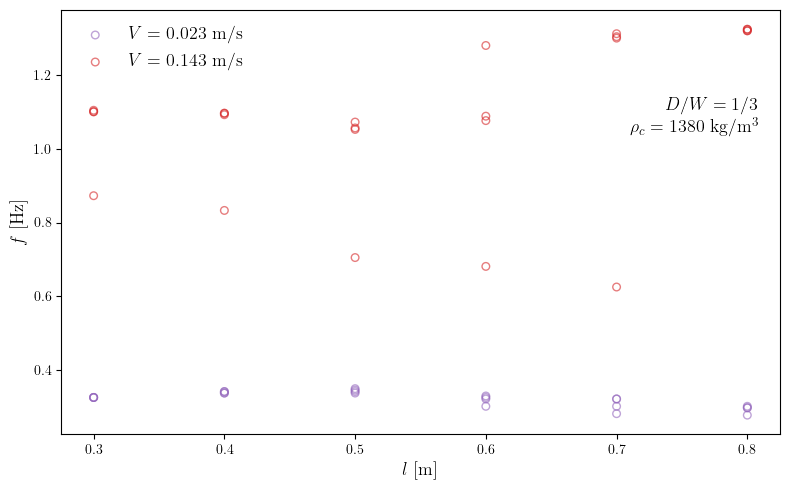

In [40]:
l_v_configs = {
    'v1': {'vin': 0.023, 'label': r'$V = 0.023$ m/s', 'color': 'tab:purple'},
    'v5': {'vin': 0.143, 'label': r'$V = 0.143$ m/s', 'color': 'tab:red'},
}

# fixed parameters for the l sensitivity configs
L_DW   = '0.333333'
L_RHOS = 1380.0
L_MU   = 1.0

def _get_sim_l(vin):
    """
    Pull all l values for fixed dw=1/3, rhoS=1380, mulabel=1
    and the given vin from sim_freq.
    Returns l_vals, freq_means, freq_stds sorted by l.
    """
    rows = []
    for (kdw, krhoS, kvin, kmu, kl), val in sim_freq.items():
        if kdw != L_DW:                                 continue
        if not np.isclose(krhoS, L_RHOS, atol=0.5):    continue
        if not np.isclose(kvin,  vin,    atol=1e-4):    continue
        if not np.isclose(kmu,   L_MU,   atol=1e-6):    continue
        rows.append((kl, val['mean'], val['std']))
    if not rows:
        return np.array([]), np.array([]), np.array([])
    rows.sort()
    return tuple(np.array([r[i] for r in rows]) for i in range(3))

# ── L sensitivity ─────────────────────────────────────────────

def _get_sim_l_individual(vin):
    """Pull (l, freq) for every repetition file."""
    points = []
    for fpath in sorted(glob.glob(os.path.join(BASE_SWEEP, '*.txt'))):
        info = parse_sweep_filename(fpath)
        if info is None:                                            continue
        if info['dw'] != L_DW:                                      continue
        if not np.isclose(info['rhoS'],    L_RHOS, atol=0.5):       continue
        if not np.isclose(info['vin'],     vin,    atol=1e-4):       continue
        if not np.isclose(info['mulabel'], L_MU,   atol=1e-6):       continue
        try:
            t, x, vx = read_sim(fpath)
            points.append((info['l'], peak_freq(t, x, vx)))
        except Exception as e:
            print(f"  WARN {os.path.basename(fpath)}: {e}")
    return points


def plot_l_vs_freq(mean=True, show=True, base_figures='../figures'):

    fig, ax = plt.subplots(figsize=(8, 5))

    for v_key, cfg in l_v_configs.items():
        col = cfg['color']

        if mean:
            l_arr, fmeans, fstds = _get_sim_l(cfg['vin'])
            if len(l_arr) == 0:
                continue
            ax.errorbar(l_arr, fmeans, yerr=fstds,
                        fmt='o', color=col, capsize=4,
                        lw=1.5, ms=6, alpha=0.8,
                        label=cfg['label'], zorder=3)
            ax.plot(l_arr, fmeans, color=col,
                    lw=1.2, alpha=0.4, zorder=2)
        else:
            pts = _get_sim_l_individual(cfg['vin'])
            if not pts:
                continue
            l_vals = np.array([p[0] for p in pts])
            f_vals = np.array([p[1] for p in pts])
            ax.scatter(l_vals, f_vals,
                       marker='o', color=col, s=30,
                       alpha=0.6, facecolors='none',
                       label=cfg['label'], zorder=3)

    ax.set_xlabel(r'$l$ [m]',  fontsize=13)
    ax.set_ylabel(r'$f$ [Hz]', fontsize=13)
    ax.legend(fontsize=13, frameon=False)
    ax.text(0.97, 0.70,
            '$D/W = 1/3$\n'
            r'$\rho_c = 1380$ kg/m$^3$',
            transform=ax.transAxes, fontsize=13,
            ha='right', va='bottom')
    fig.tight_layout()

    if show:
        plt.show()
    else:
        out_dir  = os.path.join(base_figures, 'lvsfreq')
        os.makedirs(out_dir, exist_ok=True)
        tag      = 'mean' if mean else 'all'
        out_path = os.path.join(out_dir, f'l_vs_freq_{tag}.png')
        fig.savefig(out_path, dpi=300)
        plt.close(fig)
        print(f"Saved: {out_path}")


# ── Calls ─────────────────────────────────────────────────────
plot_l_vs_freq(mean=False, show=True)

## non newtonian

In [48]:
MU_DW   = '0.333333'
MU_RHOS = 1380.0
MU_L    = 0.6
fn     = nat_freq.get((MU_DW, 1380), {}).get('mean')

nn_ratios = {
    '000': {'x': 0.00, 'xerr': 0.000},
    '025': {'x': 0.25, 'xerr': 0.0025},
    '040': {'x': 0.40, 'xerr': 0.006},
}

nn_v_configs = {
    'v1': {'label': r'$V = 0.023$ m/s', 'marker': '^', 'facecolor': 'black', 'alpha': 0.4},
    'v5': {'label': r'$V = 0.143$ m/s', 'marker': 'o', 'facecolor': 'white', 'alpha': 0.8},
}

def _get_nn(v_key):
    """Pull x, xerr, freq_mean, freq_std from nn_freq for a given v_key."""
    x_vals, x_errs, fms, fss = [], [], [], []
    for code, cfg in nn_ratios.items():
        e = nn_freq.get((code, v_key))
        if e is None:
            continue
        x_vals.append(cfg['x'])
        x_errs.append(cfg['xerr'])
        fms.append(e['mean'])
        fss.append(e['std'])
    return tuple(np.array(a) for a in (x_vals, x_errs, fms, fss))

# ── Non-Newtonian ─────────────────────────────────────────────

def _get_nn_individual(v_key):
    """Pull (x_ratio, freq) for every repetition file."""
    points = []
    for code, cfg in nn_ratios.items():
        for m_key in ['m1', 'm2', 'm3', 'm4']:
            fname = f"{code}{v_key}{m_key}.txt"
            fpath = os.path.join(BASE_NN, fname)
            if not os.path.exists(fpath):
                continue
            try:
                t, x, y = read_exp(fpath)
                vx      = np.gradient(x, t)
                points.append((cfg['x'], peak_freq(t, x, vx)))
            except Exception as e:
                print(f"  WARN {fname}: {e}")
    return points


def plot_nn_vs_freq(mean=True, show=True, base_figures='../figures'):

    fig, ax = plt.subplots(figsize=(8, 3.5))

    for v_key, cfg in nn_v_configs.items():
        marker = cfg['marker']

        if mean:
            x_arr, x_err, fm, fs = _get_nn(v_key)
            if len(x_arr) == 0:
                continue
            ax.errorbar(x_arr, fm/fn, xerr=x_err, yerr=fs/fn,
                        fmt=marker, color='black', capsize=4,
                        lw=1.5, ms=6, alpha=0.8, mfc='white',
                        label=cfg['label'])
        else:
            pts = _get_nn_individual(v_key)
            if not pts:
                continue
            x_vals = np.array([p[0] for p in pts])
            f_vals = np.array([p[1] for p in pts])
            ax.scatter(x_vals, f_vals/fn,
                       marker=marker, color='black', s=60,
                       alpha=0.6, facecolors=cfg['facecolor'],
                       label=cfg['label'])

    ax.set_xlabel(r'$m_C/m_T$', fontsize=18)
    ax.set_ylabel(r'$f/f_n$',  fontsize=18)
    ax.tick_params(axis='both', which='major', labelsize=15)
    #ax.text(0.97, 0.30,
     #       '$D/W = 1/3$\n'
      #      r'$\rho_c = 1380$ kg/m$^3$',
       #     transform=ax.transAxes, fontsize=13,
        #    ha='right', va='bottom')
    #ax.legend(fontsize=18, frameon=False)
    fig.tight_layout()

    if show:
        plt.show()
    else:
        out_dir  = os.path.join(base_figures, 'nonewtonian')
        os.makedirs(out_dir, exist_ok=True)
        tag      = 'mean' if mean else 'all'
        out_path = os.path.join(out_dir, f'nn_vs_freq_{tag}.png')
        fig.savefig(out_path, dpi=300)
        plt.close(fig)
        print(f"Saved: {out_path}")


# ── Calls ─────────────────────────────────────────────────────
plot_nn_vs_freq(mean=False,  show=False)

Saved: ../figures\nonewtonian\nn_vs_freq_all.png


## vcrit

In [20]:
BASE_VCRIT    = '../data/rawSim/vcrit'
AMP_THRESHOLD = 3.0   # % of D

def _parse_vcrit(fname):
    """'{dw}_1030_{vin}_{Re}.txt' → {'dw', 'vin', 'Re'} or None."""
    base = os.path.basename(fname).replace('.txt', '')
    m    = re.match(r'^([0-9.]+)_1030_([0-9.]+)_([0-9.]+)$', base)
    if not m:
        return None
    try:
        return {'dw': float(m.group(1)),
                'vin': float(m.group(2)),
                'Re':  float(m.group(3))}
    except ValueError:
        return None

def _classify_vcrit():
    """
    Read all vcrit files and return list of
    {'dw', 'vin', 'Re', 'oscillates'}.
    """
    records = []
    for fpath in sorted(glob.glob(os.path.join(BASE_VCRIT, '*.txt'))):
        info = _parse_vcrit(fpath)
        if info is None:
            print(f"  WARN skip: {os.path.basename(fpath)}")
            continue
        w = D / info['dw']
        try:
            x   = np.loadtxt(fpath, usecols=1, skiprows=1)
            amp = np.abs((x - w / 2) / D) * 100
            records.append({**info, 'oscillates': amp.max() > AMP_THRESHOLD})
        except Exception as e:
            print(f"  WARN {os.path.basename(fpath)}: {e}")
    return records


def plot_vcrit(show=True, base_figures='../figures'):

    records = _classify_vcrit()
    if not records:
        print("No files found.")
        return

    dw_vals  = np.array([r['dw']  for r in records])
    vin_vals = np.array([r['vin'] for r in records])
    osc      = np.array([r['oscillates'] for r in records])

    style_osc  = dict(color='tab:blue', marker='o', s=70,
                      label='Discernible oscillation',    zorder=3, alpha=0.85)
    style_nosc = dict(color='tab:red',  marker='X', s=70,
                      label='No discernible oscillation', zorder=3, alpha=0.85)

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.scatter(dw_vals[ osc], vin_vals[ osc], **style_osc)
    ax.scatter(dw_vals[~osc], vin_vals[~osc], **style_nosc)

    ax.set_xlabel(r'$D/W$',      fontsize=15)
    ax.set_ylabel(r'$V$ [m/s]',  fontsize=15)
    ax.text(0.05, 0.95, r'$\rho_c = 1030$ kg/m$^3$',
            transform=ax.transAxes, fontsize=13, va='top')
    ax.legend(fontsize=13, frameon=False, loc='upper right')
    fig.tight_layout()

    if show:
        plt.show()
    else:
        out_dir  = os.path.join(base_figures, 'vcrit')
        os.makedirs(out_dir, exist_ok=True)
        out_path = os.path.join(out_dir, 'vcrit_dw_vs_vin.png')
        fig.savefig(out_path, dpi=300)
        plt.close(fig)
        print(f"Saved: {out_path}")


# ── Calls ─────────────────────────────────────────────────────
plot_vcrit(show=False)

Saved: ../figures\vcrit\vcrit_dw_vs_vin.png
